In [2]:
def correct(path, alpha):
    for point in path:
        x, y, z = point
        if y > 0 and z > 0:
            point[1] = y - z/abs(z) * (alpha * (z**2 - 34.5**2))
            point[2] = z + y/abs(y) * (alpha * (y**2 - 34.5**2))
        elif y < 0 and z > 0:
            point[1] = y + z/abs(z) * (alpha * (z**2 - 34.5**2))
            point[2] = z - y/abs(y) * (alpha * (y**2 - 34.5**2))
        elif y < 0 and z < 0:
            point[1] = y - z/abs(z) * (alpha * (z**2 - 34.5**2))
            point[2] = z + y/abs(y) * (alpha * (y**2 - 34.5**2))
        elif y > 0 and z < 0:
            point[1] = y + z/abs(z) * (alpha * (z**2 - 34.5**2))
            point[2] = z - y/abs(y) * (alpha * (y**2 - 34.5**2))

    return path

In [3]:
import numpy as np
def toSpherical(xyz): # only works for circles
    c, y, z = xyz[:, 0], xyz[:, 1], xyz[:, 2]
    theta = y / c - (1.0 / 3.0) * np.power(y / c, 3)
    phi = z / c - (1.0 / 3.0) * np.power(z / c, 3) - (z / (2 * c)) * np.power(theta, 2)
    return np.column_stack((theta, phi))

In [4]:
import shapes

max_angle = np.pi/6
angle_inc = 0.001
space_inc = 0.01
c = 152
width = 100
alpha = 0.001
radius = 30

path = shapes.cartesianRectangle(space_inc, c, width)
# path = shapes.cartesianCircle(radius, angle_inc, c)
# path = correct(path, alpha)
spherical_data = toSpherical(path)

In [5]:
import save
save.createBinFile(spherical_data, max_angle)


Data saved to data/path.bin


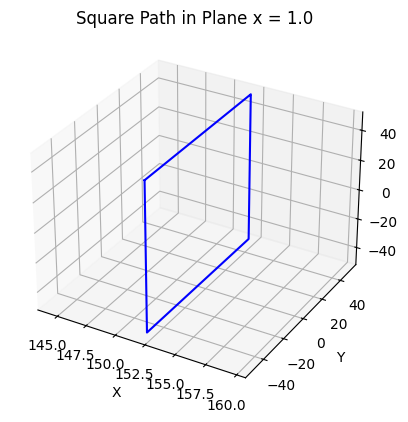

In [6]:
import matplotlib.pyplot as plt

# Plotting
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the path
ax.plot(path[:, 0], path[:, 1], path[:, 2], color='blue')

# Set labels and limits
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
# ax.set_xlim(0, 2)
# ax.set_ylim(-1.2, 1.2)
# ax.set_zlim(-1.2, 1.2)
ax.set_title('Square Path in Plane x = 1.0')

plt.show()